# CIC-IDS-2017: Exploratory Data Analysis (EDA)

## Overview
This notebook performs exploratory data analysis on the **CIC-IDS-2017** dataset using the preprocessed **MachineLearningCVE** CSV files.

### Workflow:
1. **Locate & Load Dataset**: Import all 8 CSV files with memory-efficient dtype downcasting.
2. **Data Cleaning & Sanity Checks**: Clean column whitespace, handle infinite and NaN values, address encoding quirks, and inspect duplicates.
3. **Target Variable Analysis**: Analyze class distribution, binary ratio (Benign vs Attack), and multi-class distribution across all 15 network activity labels.
4. **Feature Exploration**: Summary statistics and distributions for packet counts, packet lengths, flow durations, and TCP control flags.
5. **Correlation & Multicollinearity**: Discover redundant and collinear flow features.
6. **Key Insights & Preprocessing Guidelines**: Actionable next steps for model training pipelines.


In [1]:
import os
import glob
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.sans-serif'] = 'Segoe UI', 'DejaVu Sans', 'Arial'
warnings.filterwarnings('ignore')

print('Libraries loaded successfully!')


Libraries loaded successfully!


## 1. Locate Dataset Files
We locate all 8 CSV files in `datasets/CIC-IDS-2017/CSVs/MachineLearningCVE`.


In [2]:
# Define path to MachineLearningCVE directory
current_dir = Path.cwd()
candidate_paths = [
    current_dir / '../../datasets/CIC-IDS-2017/CSVs/MachineLearningCVE',
    current_dir / 'datasets/CIC-IDS-2017/CSVs/MachineLearningCVE',
    Path(r'd:/Swinburne Courses/Project A/datasets/CIC-IDS-2017/CSVs/MachineLearningCVE')
]

data_dir = None
for p in candidate_paths:
    if p.resolve().exists():
        data_dir = p.resolve()
        break

if data_dir is None:
    raise FileNotFoundError('Could not locate MachineLearningCVE directory. Check paths.')

csv_files = sorted(glob.glob(str(data_dir / '*.csv')))
print(f'Found {len(csv_files)} CSV files in: {data_dir}\n')
for f in csv_files:
    file_size_mb = os.path.getsize(f) / (1024 * 1024)
    print(f' - {os.path.basename(f)} ({file_size_mb:.2f} MB)')


Found 8 CSV files in: D:\Swinburne Courses\Project A\datasets\CIC-IDS-2017\CSVs\MachineLearningCVE

 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (73.55 MB)
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv (73.34 MB)
 - Friday-WorkingHours-Morning.pcap_ISCX.csv (55.62 MB)
 - Monday-WorkingHours.pcap_ISCX.csv (168.73 MB)
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv (79.25 MB)
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (49.61 MB)
 - Tuesday-WorkingHours.pcap_ISCX.csv (128.82 MB)
 - Wednesday-workingHours.pcap_ISCX.csv (214.74 MB)


## 2. Memory-Optimized Data Loading
The full dataset contains ~2.83 million rows across 79 columns. To ensure smooth performance and prevent out-of-memory errors:
- Numeric floats are downcasted from `float64` to `float32`.
- Numeric integers are downcasted with `pd.to_numeric(..., downcast='integer')`.
- Column names are stripped of extraneous whitespace.
- Encoding is handled with `latin-1` to preserve non-ASCII characters in Web Attack labels.


In [3]:
def load_and_optimize_file(file_path):
    df = pd.read_csv(file_path, encoding='latin-1', low_memory=False)
    
    # Clean whitespace in column names (e.g. ' Label' -> 'Label')
    df.columns = df.columns.str.strip()
    
    # Downcast floats and ints to save memory
    for col in df.select_dtypes(include=['float64']).columns:
        df[col] = df[col].astype('float32')
        
    for col in df.select_dtypes(include=['int64']).columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')
        
    return df

dfs = []
summary_records = []

for f in csv_files:
    filename = os.path.basename(f)
    print(f'Loading {filename}... ', end='', flush=True)
    df_temp = load_and_optimize_file(f)
    
    labels = df_temp['Label'].unique().tolist()
    summary_records.append({
        'File': filename,
        'Rows': len(df_temp),
        'Columns': df_temp.shape[1],
        'Unique Labels': len(labels),
        'Labels': ', '.join(map(str, labels))
    })
    
    dfs.append(df_temp)
    print(f'Done ({len(df_temp):,} rows)')

# Concatenate all files into a single master dataframe
df = pd.concat(dfs, ignore_index=True)
del dfs  # Free memory from intermediate list

print(f'\nTotal Dataset Loaded: {df.shape[0]:,} rows, {df.shape[1]} columns')
print(f'Total Memory Usage: {df.memory_usage().sum() / (1024**2):.2f} MB')

# Display summary table of each source file
pd.DataFrame(summary_records)


Loading Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv... Done (225,745 rows)
Loading Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv... Done (286,467 rows)
Loading Friday-WorkingHours-Morning.pcap_ISCX.csv... Done (191,033 rows)
Loading Monday-WorkingHours.pcap_ISCX.csv... Done (529,918 rows)
Loading Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv... Done (288,602 rows)
Loading Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv... Done (170,366 rows)
Loading Tuesday-WorkingHours.pcap_ISCX.csv... Done (445,909 rows)
Loading Wednesday-workingHours.pcap_ISCX.csv... Done (692,703 rows)

Total Dataset Loaded: 2,830,743 rows, 79 columns
Total Memory Usage: 701.90 MB


,File,Rows,Columns,Unique Labels,Labels
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,79,2,"BENIGN, DDoS"
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,79,2,"BENIGN, PortScan"
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,79,2,"BENIGN, Bot"
3,Monday-WorkingHours.pcap_ISCX.csv,529918,79,1,BENIGN
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,79,2,"BENIGN, Infiltration"
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,79,4,"BENIGN, Web Attack ï¿½ Brute Force, Web Attack..."
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,79,3,"BENIGN, FTP-Patator, SSH-Patator"
7,Wednesday-workingHours.pcap_ISCX.csv,692703,79,6,"BENIGN, DoS slowloris, DoS Slowhttptest, DoS H..."


## 3. Data Cleaning & Sanity Checks
Key dataset properties to inspect and handle:
1. **Label standardization**: Clean non-standard dash characters in Web Attack labels.
2. **Infinite values**: Division by zero occurs in `Flow Bytes/s` and `Flow Packets/s` when `Flow Duration == 0`.
3. **Missing (NaN) values**: Identifying null values and deciding on an imputation or dropping strategy.
4. **Duplicate rows**: Repetitive flow captures.


In [4]:
# 1. Clean and normalize Label names
def clean_label(label):
    if not isinstance(label, str):
        return label
    label = label.strip()
    # Normalize unicode / non-ascii characters (like \x96 en-dash) to standard hyphens
    label = re.sub(r'[^\x00-\x7F]+', '-', label)
    label = re.sub(r'\s*-\s*', ' - ', label)
    return label

df['Label'] = df['Label'].apply(clean_label)

# 2. Check for Infinite values
num_cols = df.select_dtypes(include=[np.number]).columns
inf_counts = np.isinf(df[num_cols]).sum()
inf_cols = inf_counts[inf_counts > 0]
print('Columns containing infinite values:')
print(inf_cols)

# Replace Inf and -Inf with NaN for clean downstream processing
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# 3. Check for Missing (NaN) values
nan_counts = df.isnull().sum()
nan_cols = nan_counts[nan_counts > 0]
print('\nColumns containing NaN values:')
print(nan_cols)

# 4. Check for duplicate rows
num_duplicates = df.duplicated().sum()
print(f'\nDuplicate rows found: {num_duplicates:,} ({num_duplicates / len(df) * 100:.2f}%)')


Columns containing infinite values:
Flow Bytes/s      1509
Flow Packets/s    2867
dtype: int64

Columns containing NaN values:
Flow Bytes/s      2867
Flow Packets/s    2867
dtype: int64

Duplicate rows found: 330,995 (11.69%)


## 4. Target Variable Analysis (Class Distribution)
Analyzing:
- **Binary Classification**: Benign vs. Attack
- **Multi-class Distribution**: All 15 distinct network activity categories


=== Multi-Class Distribution ===


,Count,Percentage (%)
Label,,
BENIGN,2273097,80.3004
DoS Hulk,231073,8.1630
PortScan,158930,5.6144
DDoS,128027,4.5227
DoS GoldenEye,10293,0.3636
FTP - Patator,7938,0.2804
SSH - Patator,5897,0.2083
DoS slowloris,5796,0.2048
DoS Slowhttptest,5499,0.1943


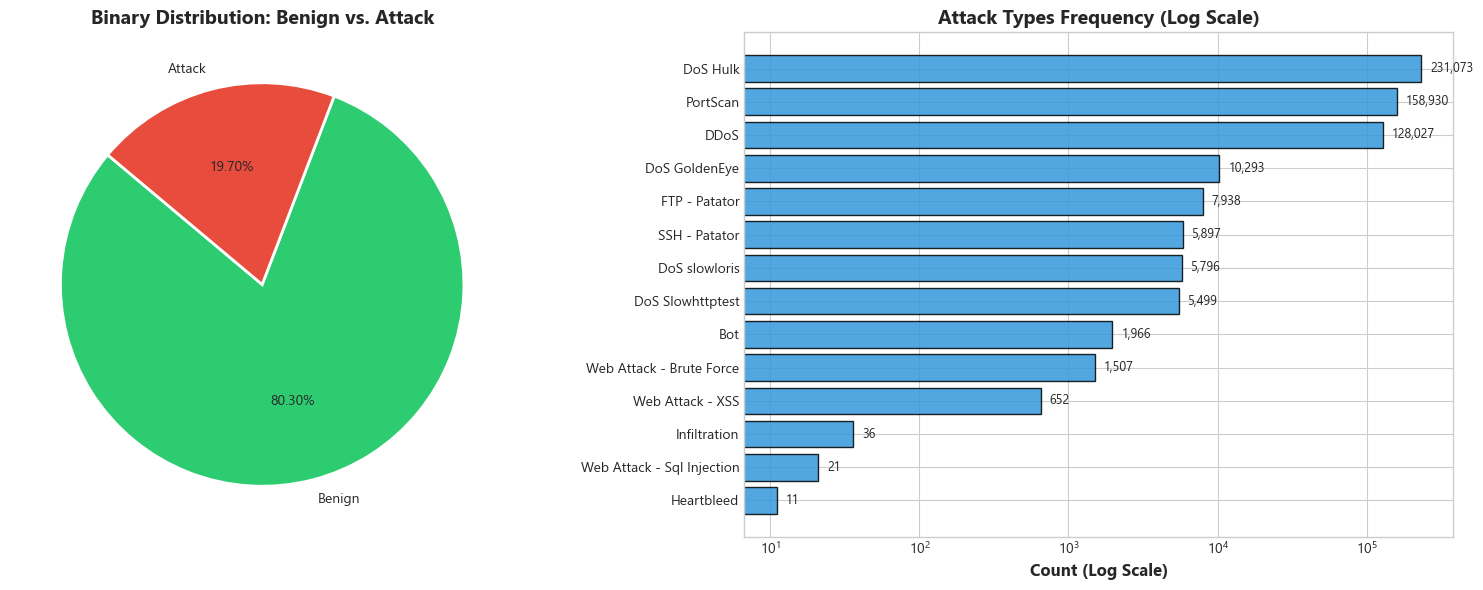

In [5]:
# Create Binary Target: 0 = Benign, 1 = Attack
df['Is_Attack'] = (df['Label'] != 'BENIGN').astype(int)

# Multi-class frequency table
label_counts = df['Label'].value_counts()
label_perc = df['Label'].value_counts(normalize=True) * 100

dist_df = pd.DataFrame({
    'Count': label_counts,
    'Percentage (%)': label_perc.round(4)
})
print('=== Multi-Class Distribution ===')
display(dist_df)

# Plot 1: Binary Distribution Donut Chart
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

binary_counts = df['Is_Attack'].value_counts()
axes[0].pie(
    binary_counts,
    labels=['Benign', 'Attack'],
    autopct='%1.2f%%',
    startangle=140,
    colors=['#2ecc71', '#e74c3c'],
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[0].set_title('Binary Distribution: Benign vs. Attack', fontsize=14, fontweight='bold')

# Plot 2: Multi-class Distribution (Log Scale due to extreme imbalance)
attack_only = label_counts[label_counts.index != 'BENIGN'].sort_values(ascending=True)

y_pos = range(len(attack_only))
axes[1].barh(y_pos, attack_only.values, color='#3498db', edgecolor='black', alpha=0.85)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(attack_only.index, fontsize=10)
axes[1].set_xscale('log')
axes[1].set_xlabel('Count (Log Scale)', fontsize=12, fontweight='bold')
axes[1].set_title('Attack Types Frequency (Log Scale)', fontsize=14, fontweight='bold')

for i, v in enumerate(attack_only.values):
    axes[1].text(v * 1.15, i, f'{v:,}', va='center', fontsize=9)

plt.tight_layout()
plt.show()


## 5. Network Flow Feature Analysis
The 78 statistical flow features fall into key network domain groups:
1. **Flow Durations & Packet Rates**: `Flow Duration`, `Flow Bytes/s`, `Flow Packets/s`
2. **Forward vs. Backward Packet Sizes**: `Total Length of Fwd Packets`, `Fwd Packet Length Mean`, `Bwd Packet Length Mean`
3. **Inter-Arrival Times (IAT)**: `Flow IAT Mean`, `Flow IAT Max`, `Fwd IAT Mean`
4. **TCP Control Flags**: `FIN`, `SYN`, `RST`, `PSH`, `ACK`, `URG`


In [6]:
# Select key representative features
key_features = [
    'Flow Duration',
    'Total Fwd Packets',
    'Total Backward Packets',
    'Total Length of Fwd Packets',
    'Total Length of Bwd Packets',
    'Fwd Packet Length Mean',
    'Bwd Packet Length Mean',
    'Flow Bytes/s',
    'Flow Packets/s',
    'Flow IAT Mean',
    'SYN Flag Count',
    'ACK Flag Count',
    'PSH Flag Count'
]

display(df[key_features].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])


,count,mean,std,min,50%,max
Flow Duration,2830743.0,1.478566e+07,3.365374e+07,-13.0,31316.000000,1.200000e+08
Total Fwd Packets,2830743.0,9.361160e+00,7.496728e+02,1.0,2.000000,2.197590e+05
Total Backward Packets,2830743.0,1.039377e+01,9.973883e+02,0.0,2.000000,2.919220e+05
Total Length of Fwd Packets,2830743.0,5.493024e+02,9.993589e+03,0.0,62.000000,1.290000e+07
Total Length of Bwd Packets,2830743.0,1.616264e+04,2.263088e+06,0.0,123.000000,6.554530e+08
Fwd Packet Length Mean,2830743.0,5.820191e+01,1.860912e+02,0.0,34.000000,5.940857e+03
Bwd Packet Length Mean,2830743.0,3.059494e+02,6.052568e+02,0.0,72.000000,5.800500e+03
Flow Bytes/s,2827876.0,1.491718e+06,2.594016e+07,-261000000.0,4586.600586,2.071000e+09
Flow Packets/s,2827876.0,7.085424e+04,2.544154e+05,-2000000.0,109.475998,4.000000e+06
Flow IAT Mean,2830743.0,1.298448e+06,4.507944e+06,-13.0,11438.841797,1.200000e+08


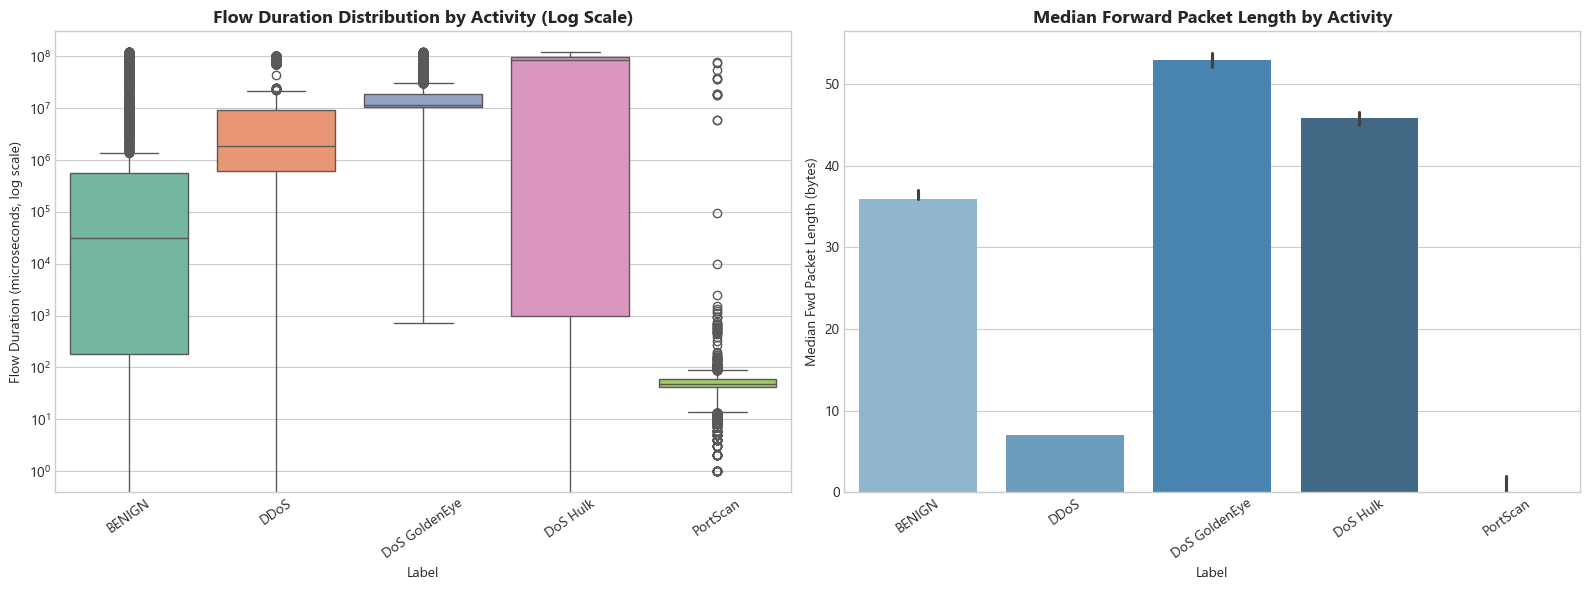

In [7]:
# Compare Flow Duration and Packet Lengths across top attack classes
top_classes = ['BENIGN', 'DoS Hulk', 'PortScan', 'DDoS', 'DoS GoldenEye', 'FTP-Patator', 'SSH-Patator']
sample_df = df[df['Label'].isin(top_classes)].groupby('Label', group_keys=False).apply(
    lambda x: x.sample(min(len(x), 5000), random_state=42)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Flow Duration boxplot (log scale)
sns.boxplot(
    data=sample_df,
    x='Label',
    y='Flow Duration',
    palette='Set2',
    ax=axes[0]
)
axes[0].set_yscale('log')
axes[0].tick_params(axis='x', rotation=35)
axes[0].set_title('Flow Duration Distribution by Activity (Log Scale)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Flow Duration (microseconds, log scale)')

# Mean Packet Length comparison
sns.barplot(
    data=sample_df,
    x='Label',
    y='Fwd Packet Length Mean',
    palette='Blues_d',
    estimator=np.median,
    ax=axes[1]
)
axes[1].tick_params(axis='x', rotation=35)
axes[1].set_title('Median Forward Packet Length by Activity', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Median Fwd Packet Length (bytes)')

plt.tight_layout()
plt.show()


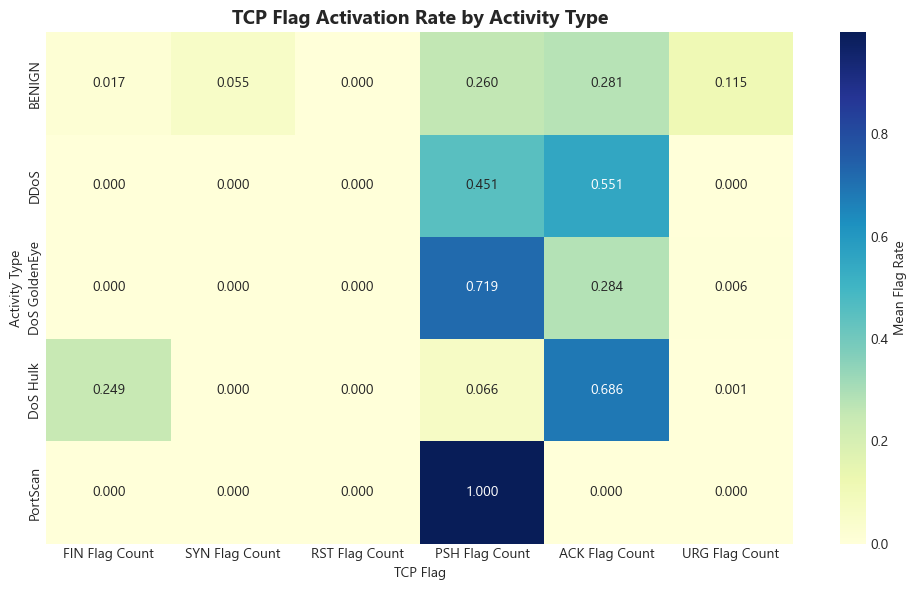

In [8]:
# TCP Flags distribution across activities
flag_cols = ['FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count']

# Mean flag activation per activity
flags_by_class = sample_df.groupby('Label')[flag_cols].mean()

plt.figure(figsize=(10, 6))
sns.heatmap(flags_by_class, annot=True, fmt='.3f', cmap='YlGnBu', cbar_kws={'label': 'Mean Flag Rate'})
plt.title('TCP Flag Activation Rate by Activity Type', fontsize=14, fontweight='bold')
plt.ylabel('Activity Type')
plt.xlabel('TCP Flag')
plt.tight_layout()
plt.show()


## 6. Correlation & Multicollinearity
Many features in CIC-IDS-2017 are derived from each other (e.g. forward packet totals, subflow totals, header lengths, packet length means and maximums). We compute the Pearson correlation matrix to visualize redundant features.


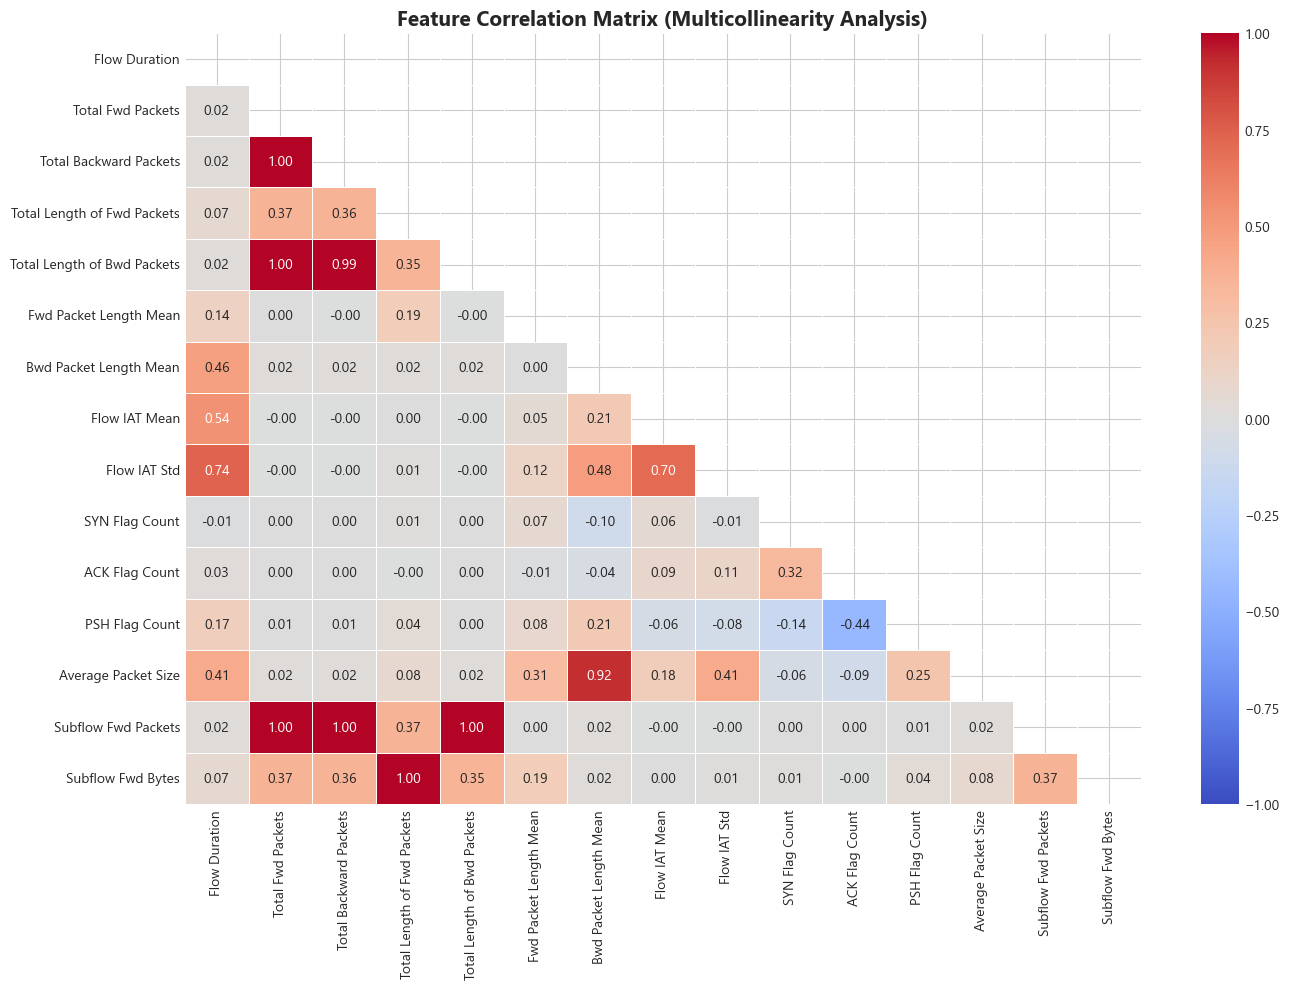

In [9]:
# Compute correlation matrix on sample for speed and efficiency
features_for_corr = [
    'Flow Duration',
    'Total Fwd Packets',
    'Total Backward Packets',
    'Total Length of Fwd Packets',
    'Total Length of Bwd Packets',
    'Fwd Packet Length Mean',
    'Bwd Packet Length Mean',
    'Flow IAT Mean',
    'Flow IAT Std',
    'SYN Flag Count',
    'ACK Flag Count',
    'PSH Flag Count',
    'Average Packet Size',
    'Subflow Fwd Packets',
    'Subflow Fwd Bytes'
]

# Clean feature subset (drop NaN for correlation)
corr_matrix = df[features_for_corr].dropna().corr()

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title('Feature Correlation Matrix (Multicollinearity Analysis)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Key Findings & Preprocessing Recommendations

### Findings
1. **Severe Class Imbalance**:
   - ~80.3% of records are `BENIGN`.
   - Major attacks like `DoS Hulk`, `PortScan`, and `DDoS` have tens of thousands of samples.
   - Rare attacks like `Heartbleed` (11 samples), `Infiltration` (36 samples), and `Web Attack - Sql Injection` (21 samples) are heavily underrepresented.
2. **Infinite Values**:
   - `Flow Bytes/s` and `Flow Packets/s` have divisions by zero when `Flow Duration == 0`.
   - These must be replaced with `NaN` and imputed (or rows dropped).
3. **High Multicollinearity**:
   - Features like `Total Fwd Packets` and `Subflow Fwd Packets` are practically identical (correlation = 1.00).
   - Duplicate header columns exist in raw files (e.g. `Fwd Header Length` appears twice).
4. **Duplicate Rows**:
   - The dataset contains non-trivial numbers of duplicate flow records resulting from repetitive background polling or scanner retries.

### Actionable Recommendations for Machine Learning Pipeline:
- **Resampling / Class Weights**: Use SMOTE, balanced class weights, or focal loss to prevent models from ignoring rare classes (`Heartbleed`, `Infiltration`).
- **Feature Selection**: Drop perfectly collinear features (e.g. `Subflow *` duplicates, duplicate `Fwd Header Length`).
- **Robust Scaling**: Extreme outliers exist in `Flow Duration` and packet lengths; use `RobustScaler` or log transforms (`log1p`).
- **Train/Test Splitting**: Stratify splits by `Label` to ensure rare attack classes are represented in both train and test sets.


---
# 8. Data Cleaning & Feature Transformation Pipeline

To standardize our feature representation across heterogeneous intrusion detection datasets, we match the legacy CIC-IDS-2017 statistical features against the standard NetFlow common feature set defined in `datasets/feature_dataset.xlsx` (`common_features` sheet) based on their semantic descriptions.

### Feature Matching Table (based on descriptions):

| Common Feature Name (`feature_dataset.xlsx`) | Common Feature Description | Legacy CIC-IDS-2017 Feature | Description & Transformation Logic |
| :--- | :--- | :--- | :--- |
| **`FLOW DURATION MILLISECONDS`** | Flow duration in milliseconds | `Flow Duration` | Flow duration in microseconds (converted via `Flow Duration / 1000`) |
| **`IN BYTES`** | Incoming number of bytes | `Total Length of Fwd Packets` | Total size of packets in forward direction |
| **`OUT BYTES`** | Outgoing number of bytes | `Total Length of Bwd Packets` | Total size of packets in backward direction |
| **`IN PKTS`** | Incoming number of packets | `Total Fwd Packets` | Total packets in forward direction |
| **`OUT PKTS`** | Outgoing number of packets | `Total Backward Packets` | Total packets in backward direction |
| **`SRC TO DST SECOND BYTES`** | Src to dst Bytes/sec | `Flow Bytes/s` | Number of flow bytes per second |
| **`SRC TO DST AVG THROUGHPUT`** | Src to dst average thpt (bps) | `Flow Bytes/s` | Bytes/sec converted to bps via `Flow Bytes/s * 8` |
| **`TCP WIN MAX IN`** | Max TCP Window (src->dst) | `Init_Win_bytes_forward` | Initial TCP window bytes in forward direction |
| **`TCP WIN MAX OUT`** | Max TCP Window (dst->src) | `Init_Win_bytes_backward` | Initial TCP window bytes in backward direction |
| **`Attack_Type`** *(Target)* | Attack activity name | `Label` | Sanitized label (`BENIGN`, `DoS Hulk`, `PortScan`, etc.) |
| **`Attack_Indicator`** *(Target)* | Binary attack indicator | `Is_Attack` | 0 for BENIGN, 1 for Attack |
| **`Dataset`** *(Provenance)* | Source dataset origin | - | Constant `'CIC-IDS-2017'` |

> **Dropping Legacy Features:** All other 65+ redundant, collinear, or extractor-specific statistical features (e.g. packet length moments, inter-arrival time moments, subflow packet counts, bulk transmission rates) are dropped.

In [ ]:
def clean_cic_label(lbl):
    if not isinstance(lbl, str):
        return 'BENIGN'
    lbl = lbl.strip()
    lbl = re.sub(r'[^\x00-\x7F]+', '-', lbl)
    lbl = re.sub(r'\s+', ' ', lbl)
    return lbl

def transform_cic_file(file_path):
    """
    Loads and transforms a single CIC-IDS-2017 CSV file into the standard common feature set.
    """
    cdf = pd.read_csv(file_path, encoding='latin-1', low_memory=False)
    cdf.columns = cdf.columns.str.strip()
    
    # 1. Clean corrupted records (infinite or NaN Flow Bytes/s, negative durations)
    fb = pd.to_numeric(cdf['Flow Bytes/s'], errors='coerce')
    valid_mask = ~np.isinf(fb) & ~fb.isna() & (cdf['Flow Duration'] >= 0)
    cdf = cdf[valid_mask].copy()
    
    clean_cdf = pd.DataFrame()
    # 2. Map features based on Common Features specification
    clean_cdf['FLOW DURATION MILLISECONDS'] = (cdf['Flow Duration'] / 1000.0).astype(np.float32)
    clean_cdf['IN BYTES'] = cdf['Total Length of Fwd Packets'].astype(np.int64)
    clean_cdf['OUT BYTES'] = cdf['Total Length of Bwd Packets'].astype(np.int64)
    clean_cdf['IN PKTS'] = cdf['Total Fwd Packets'].astype(np.int64)
    clean_cdf['OUT PKTS'] = cdf['Total Backward Packets'].astype(np.int64)
    clean_cdf['SRC TO DST SECOND BYTES'] = pd.to_numeric(cdf['Flow Bytes/s'], errors='coerce').fillna(0.0).astype(np.float32)
    clean_cdf['SRC TO DST AVG THROUGHPUT'] = (clean_cdf['SRC TO DST SECOND BYTES'] * 8.0).astype(np.float32)
    clean_cdf['TCP WIN MAX IN'] = cdf['Init_Win_bytes_forward'].astype(np.int64)
    clean_cdf['TCP WIN MAX OUT'] = cdf['Init_Win_bytes_backward'].astype(np.int64)
    
    # 3. Targets and Provenance
    lbls = cdf['Label'].apply(clean_cic_label)
    clean_cdf['Attack_Type'] = lbls
    clean_cdf['Attack_Indicator'] = (lbls != 'BENIGN').astype(np.int32)
    clean_cdf['Dataset'] = 'CIC-IDS-2017'
    
    return clean_cdf

print("Transforming all 8 CIC-IDS-2017 files...")
cic_transformed_dfs = []
for f in csv_files:
    f_name = os.path.basename(f)
    df_part = transform_cic_file(f)
    print(f"  - {f_name}: {len(df_part):,} valid rows")
    cic_transformed_dfs.append(df_part)

df_cic_derived = pd.concat(cic_transformed_dfs, ignore_index=True)
print(f"\nTotal Derived CIC-IDS-2017 Dataset: {df_cic_derived.shape[0]:,} rows x {df_cic_derived.shape[1]} columns")
display(df_cic_derived.head())

# Export derived CIC dataset
datasets_root = Path(r'd:/Swinburne Courses/Project A/datasets')
cic_derived_path = datasets_root / 'CIC_IDS_2017_derived.csv'
df_cic_derived.to_csv(cic_derived_path, index=False)
print(f"-> Exported derived CIC dataset to: {cic_derived_path.resolve()}")


---
# 9. Unified Multi-Dataset Export (`uniform_IDS.csv`)

Per project specifications, **no pre-splitting is applied**. We merge the derived CIC-IDS-2017 dataset with the derived UNSW-NB15 dataset into a single, cohesive benchmark file named `uniform_IDS.csv`.


In [ ]:
unsw_derived_path = datasets_root / 'UNSW_NB15_derived.csv'
uniform_export_path = datasets_root / 'uniform_IDS.csv'

if unsw_derived_path.exists():
    print(f"Loading derived UNSW-NB15 from: {unsw_derived_path.resolve()}...")
    df_unsw_derived = pd.read_csv(unsw_derived_path)
    print(f"UNSW-NB15 shape: {df_unsw_derived.shape[0]:,} rows x {df_unsw_derived.shape[1]} columns")
    
    print("Combining both datasets into uniform_IDS.csv...")
    df_uniform = pd.concat([df_unsw_derived, df_cic_derived], ignore_index=True)
    df_uniform.to_csv(uniform_export_path, index=False)
    print(f"-> Saved unified dataset to: {uniform_export_path.resolve()}")
    print(f"   Total shape: {df_uniform.shape[0]:,} rows x {df_uniform.shape[1]} columns")
    print("\nDataset Breakdown:")
    print(df_uniform['Dataset'].value_counts())
    print("\nAttack Indicator Breakdown:")
    print(df_uniform['Attack_Indicator'].value_counts())
    print("\nTop Attack Types in Unified Dataset:")
    print(df_uniform['Attack_Type'].value_counts().head(10))
else:
    print(f"UNSW-NB15 derived file not yet found at {unsw_derived_path}. Please execute unsw_nb15.ipynb to generate it.")
